# 01 · Risk model on synthetic data

This notebook rebuilds the MaintainAI risk model from scratch: it turns the SQLite database into weekly training snapshots, trains a `RandomForestRegressor`, evaluates it on machines it has never seen, and saves `risk_model.pkl` for the app.

> **Read this first.** `factory_maintenance.db` is synthetic, and there are no real failure labels. The training target is a **designed proxy formula** (weighted, normalised features plus noise), defined in [`risk_features.py`](../risk_features.py). A high score here means the pipeline can learn a known relationship from the kind of data the app sees. It does **not** show that the model predicts real machine failures. That would need real historical failure records.

The same code is in `training/train_risk_model.py`. This notebook calls it step by step so every number below can be reproduced from the command line.

In [1]:
import sqlite3, sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "training"), str(ROOT / "notebooks")]
import risk_features as rf
import train_risk_model as T
import plot_style as ps

ps.apply()
OUT = ROOT / "results" / "risk_model"
DB = ROOT / "factory_maintenance.db"

## 1. The data

Four tables: `Machines`, `Maintenance_Log`, `Failure_Log`, `Sensor_Readings` (weekly temperature and vibration). All of it was generated with healthy, average and high-risk machine profiles, so there are real patterns for a model to find.

In [2]:
with sqlite3.connect(DB) as conn:
    tables = rf.load_tables(conn)
ref = rf.reference_date(tables)
summary = {k: {"rows": len(v),
               "first": v["date"].min().date() if "date" in v else "",
               "last": v["date"].max().date() if "date" in v else ""} for k, v in tables.items()}
print("reference date (latest record):", ref.date())
pd.DataFrame(summary).T

reference date (latest record): 2026-09-10


,rows,first,last
machines,50,,
maintenance,290,2024-09-10,2026-09-06
failures,153,2024-09-20,2026-09-10
sensors,4915,2024-09-12,2026-09-03


## 2. Features, as of any date

`risk_features.features_at(tables, as_of)` computes the 8 model inputs for every machine using only records dated on or before `as_of`. The app uses the same function, with `as_of` set to the latest record date. Using the wall clock instead would make every machine drift towards Critical as the frozen demo data ages.

| feature | definition |
|---|---|
| `age_years` | years since install |
| `operating_hours` | hour-meter reading. Past values are back-estimated assuming even use since install (there is no meter history). |
| `days_since_maintenance` | days since the last maintenance entry |
| `failure_count`, `total_downtime` | failures and their downtime hours, trailing 12 months |
| `maintenance_frequency` | maintenance events per year, trailing 12 months |
| `temperature`, `vibration` | sensor means, trailing 56 days |

In [3]:
rf.current_features(tables)[rf.FEATURES].describe().T[["min", "50%", "max"]].round(1)

,min,50%,max
age_years,1.1,3.5,9.3
operating_hours,2955.0,12255.0,41383.0
days_since_maintenance,4.0,55.0,192.0
failure_count,0.0,1.0,6.0
total_downtime,0.0,22.2,145.7
maintenance_frequency,1.0,3.0,5.0
temperature,42.0,50.9,79.4
vibration,2.3,4.6,10.8


## 3. The proxy target

Each feature is mapped to 0–1 between a fixed *healthy* and *bad* value (clipped). The values are combined with weights that sum to 1, then Gaussian noise (σ = 4 points) is added for variation the features don't capture:

$$\text{risk} = \text{clip}\Big(100 \sum_i w_i \cdot \text{clip}\big(\tfrac{x_i - \text{lo}_i}{\text{hi}_i - \text{lo}_i}, 0, 1\big) + \varepsilon,\ 0,\ 100\Big), \qquad \varepsilon \sim \mathcal N(0, 4^2)$$

The ranges are engineering judgements fixed in code, not fitted to the data. For example, vibration goes from 2 mm/s (fine) to 8 mm/s (severe), roughly following ISO 10816 zones. `maintenance_frequency` is inverted: 6+ services a year counts as healthy.

In [4]:
pd.DataFrame([(f, w, lo, hi) for f, (w, lo, hi) in rf.PROXY_TERMS.items()],
             columns=["feature", "weight", "healthy (0)", "bad (1)"]).set_index("feature")

,weight,healthy (0),bad (1)
feature,,,
failure_count,0.22,0.0,6.0
days_since_maintenance,0.16,0.0,180.0
vibration,0.16,2.0,8.0
temperature,0.12,40.0,85.0
total_downtime,0.10,0.0,150.0
age_years,0.10,0.0,12.0
operating_hours,0.08,0.0,40000.0
maintenance_frequency,0.06,6.0,0.0


## 4. Weekly snapshots

The fleet has only 50 machines, so one row per machine is far too few to train on. Instead, every machine's features are reconstructed **as of every week**. Snapshots start one full year after the first record, so the 12-month counts are never cut short.

In [5]:
df = T.build_dataset(DB)
print(f"{len(df):,} snapshots · {df.machine_id.nunique()} machines · {df.snapshot_date.nunique()} weeks "
      f"({df.snapshot_date.min().date()} → {df.snapshot_date.max().date()})")
df[["machine_id", "snapshot_date", *rf.FEATURES, "risk"]].head()

2,650 snapshots · 50 machines · 53 weeks (2025-09-11 → 2026-09-10)


,machine_id,snapshot_date,age_years,operating_hours,days_since_maintenance,failure_count,total_downtime,maintenance_frequency,temperature,vibration,risk
0,MCH-001,2025-09-11,3.57,11701.0,7,2,93.2,3.00,46.66,4.19,31.3
1,MCH-002,2025-09-11,0.81,2142.0,25,0,0.0,4.93,43.25,2.86,3.4
2,MCH-003,2025-09-11,0.29,826.0,11,0,0.0,6.82,48.19,3.18,9.7
3,MCH-004,2025-09-11,1.18,2803.0,3,0,0.0,4.00,51.50,3.23,13.9
4,MCH-005,2025-09-11,6.75,30145.0,94,2,80.9,2.00,56.39,6.16,44.4


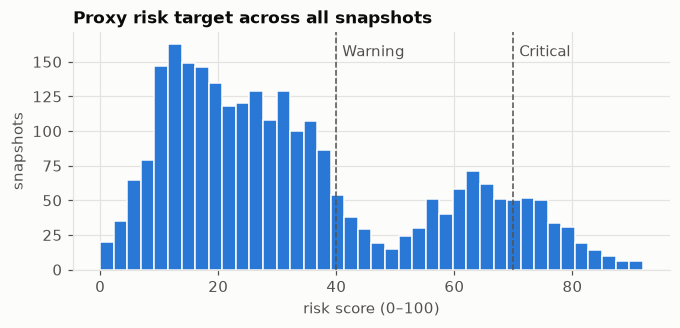

In [6]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(df["risk"], bins=40, color=ps.SERIES[0], edgecolor=ps.SURFACE, linewidth=1)
for x, name in ((40, "Warning"), (70, "Critical")):
    ax.axvline(x, color=ps.TEXT_2, lw=1, ls="--")
    ax.text(x + 1, ax.get_ylim()[1] * .9, name, color=ps.TEXT_2)
ax.set(title="Proxy risk target across all snapshots", xlabel="risk score (0–100)", ylabel="snapshots")
ps.save(fig, OUT / "target_distribution.png")

## 5. Evaluation on unseen machines

Snapshots of the same machine in neighbouring weeks are almost identical. A random 80/20 row split would put near-copies of the test rows in the training set and flatter the scores, so the main evaluation **holds out whole machines** (10 of 50). Because 10 machines is a small test set, a 5-fold group cross-validation is also reported.

Reference points:
- **Mean baseline**: always predicts the training average.
- **Linear regression**: the proxy is close to a weighted sum, so a linear model is expected to do well here.
- **Noise ceiling**: the noise-free formula scored against the noisy target. No model can do better on average.

In [7]:
report = T.evaluate(df)
cv = report["group_5fold_cv_random_forest"]
rows = {**report["held_out_machines"],
        "Random Forest · 5-fold group CV (mean)": {k: v["mean"] for k, v in cv.items()},
        "Random Forest · random row split (leaky)": report["random_row_split_random_forest"],
        "Noise ceiling (true formula)": report["noise_ceiling"]}
print(f"5-fold group CV MAE spread: ±{cv['MAE']['std']}")
pd.DataFrame(rows).T

5-fold group CV MAE spread: ±0.371


,MAE,RMSE,R2
Mean baseline,21.890,27.340,-0.217
Linear regression,3.530,4.490,0.967
Random Forest,4.640,5.850,0.944
Random Forest · 5-fold group CV (mean),3.888,4.982,0.937
Random Forest · random row split (leaky),3.470,4.340,0.959
Noise ceiling (true formula),3.320,4.190,0.971


**Reading the table.**
- The Random Forest gets within about 4–5 points of the target on machines it never saw (one 10-machine split, plus a steadier 5-fold average). That is not far above the noise ceiling (about 3.3), so most of the learnable signal is captured.
- Linear regression does better, which is expected: the target *is* almost a weighted sum of the features. The Random Forest is kept because a real failure process is unlikely to be linear, because it handles thresholds and interactions without feature engineering, and because `shap.TreeExplainer` gives exact per-machine explanations for it in the app.
- **Old vs new.** The previous model reported MAE 3.37 / R² 0.959 on a *random row split*. The same leaky split gives about the same here (see table). The machine-level numbers are the honest ones.

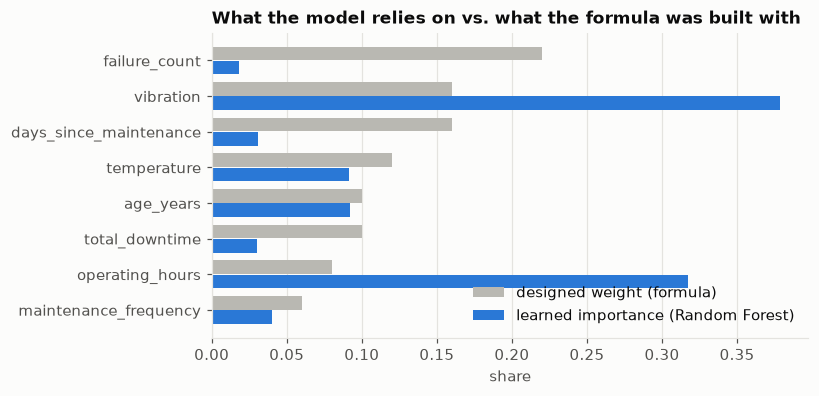

In [8]:
imp = pd.DataFrame({"model importance": pd.Series(report["feature_importance"]),
                    "designed weight": pd.Series(report["proxy_weights"])}).sort_values("designed weight")
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(imp))
ax.barh(y + .2, imp["designed weight"], height=.38, color=ps.NEUTRAL, label="designed weight (formula)")
ax.barh(y - .2, imp["model importance"], height=.38, color=ps.SERIES[0], label="learned importance (Random Forest)")
ax.set_yticks(y, imp.index)
ax.grid(axis="y", visible=False)
ax.set(title="What the model relies on vs. what the formula was built with", xlabel="share")
ax.legend(loc="lower right")
ps.save(fig, OUT / "feature_importance.png")

**The model does not rely on the features the formula weighted most.** Failure count has the largest weight (0.22) but almost no importance, while vibration and operating hours dominate. The reason is **collinearity in the synthetic data**: the generator drew every machine from a healthy, average or high-risk profile, and that profile moves almost every feature together.

In [9]:
pairs = [("age_years", "operating_hours"), ("operating_hours", "vibration"), ("temperature", "vibration"),
         ("failure_count", "total_downtime"), ("failure_count", "operating_hours")]
corr = df[rf.FEATURES].corr()
pd.Series({f"{a} ~ {b}": round(corr.at[a, b], 2) for a, b in pairs}, name="correlation").to_frame()

,correlation
age_years ~ operating_hours,0.99
operating_hours ~ vibration,0.93
temperature ~ vibration,0.94
failure_count ~ total_downtime,0.92
failure_count ~ operating_hours,0.71


With features this entangled, the forest can reach almost the same predictions by using vibration and hours as a stand-in for the whole profile, and that is what it does. Changing `max_features` doesn't fix this (with 1.0 the model leans on vibration even more). The data simply can't tell the model *which* of the correlated features the formula used.

**Consequence for the app.** The per-machine explanations come from SHAP, so they explain *the model*, not the formula. When a machine's explanation credits vibration, the formula may have scored it partly on its failures. With real data, fixing this would take a more varied fleet (old machines with low vibration, new machines that fail), not a different algorithm.

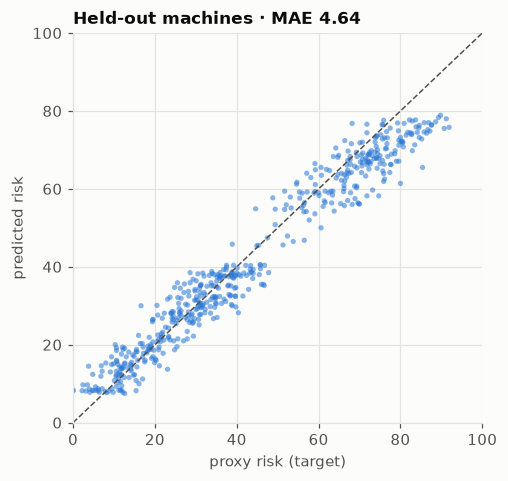

In [10]:
pred = report["_test_predictions"]
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.scatter(pred["actual"], pred["predicted"], s=12, alpha=.55, color=ps.SERIES[0], edgecolor="none")
ax.plot([0, 100], [0, 100], color=ps.TEXT_2, lw=1, ls="--")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="proxy risk (target)", ylabel="predicted risk",
       title=f"Held-out machines · MAE {report['held_out_machines']['Random Forest']['MAE']}")
ps.save(fig, OUT / "actual_vs_predicted.png")

## 6. Train the final model and save it

After evaluation, the model is refit on **all** snapshots for the app. The bundle keeps the format `data.py` expects: `{"model", "features", "thresholds"}`.

In [11]:
bundle = T.train_final(df)
joblib.dump(bundle, ROOT / "risk_model.pkl", compress=3)
T.save_results(report)
print({k: (type(v).__name__ if k == "model" else v) for k, v in bundle.items()})

{'model': 'RandomForestRegressor', 'features': ['age_years', 'operating_hours', 'days_since_maintenance', 'failure_count', 'total_downtime', 'maintenance_frequency', 'temperature', 'vibration'], 'thresholds': {'warning': 40, 'critical': 70}}


## 7. Scoring today's fleet, with explanations

The app does exactly this: features as of the latest record, a model prediction, and SHAP values that split each prediction into per-feature contributions (fleet average + contributions = score).

{'Normal': 33, 'Warning': 11, 'Critical': 6}


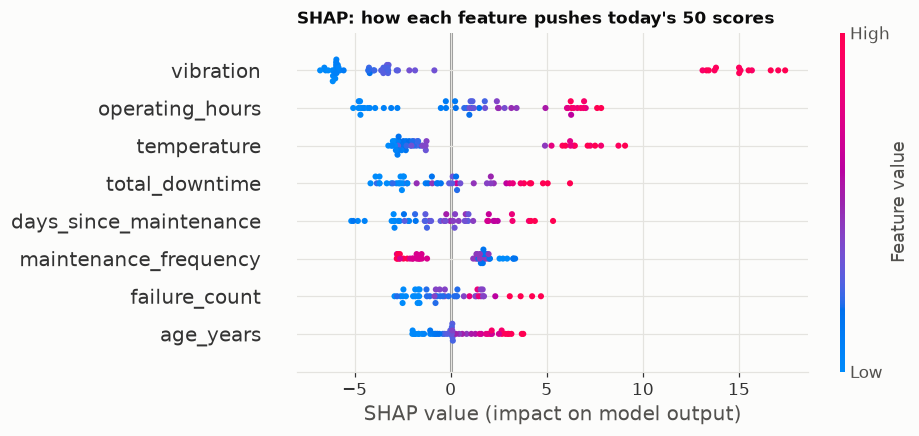

In [12]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # shap imports tqdm.auto
import shap
cur =rf.current_features(tables)
cur["risk"] = bundle["model"].predict(cur[rf.FEATURES]).clip(0, 100).round(1)
cur["band"] = pd.cut(cur["risk"].round(), [-1, 39, 69, 101], labels=["Normal", "Warning", "Critical"])
print(cur["band"].value_counts().to_dict())
sv = shap.TreeExplainer(bundle["model"])(cur[rf.FEATURES])
shap.plots.beeswarm(sv, show=False)
plt.title("SHAP: how each feature pushes today's 50 scores", loc="left")
plt.gcf().set_size_inches(7.5, 4)
ps.save(plt.gcf(), OUT / "shap_summary.png")

## 8. Limitations

- **Synthetic data, designed target.** The model reproduces a formula I wrote. Its accuracy says nothing about real failures. To validate against reality, the target would have to be an observed outcome, for example "failed within the next 30 days", taken from real maintenance history. Notebooks 02 and 03 show that kind of setup on public benchmark datasets.
- **Small fleet.** 50 machines, of which 10 are held out per split, so the metrics have noticeable variance (see the CV spread above).
- **Back-estimated hours.** Past operating hours assume even use since install.
- **Thresholds.** Warning 40 / Critical 70 are working assumptions, not calibrated to any cost of failure.